# LightGBM: Fast Leaf-Wise Boosting for Churn

**Family:** Supervised learning | **Level:** Intermediate | **Dataset:** `telco_churn` | **Runs on:** CPU, about 2 minute(s)

Grow trees leaf by leaf on histogram bins and handle categories natively.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How leaf-wise growth differs from level-wise growth
- Why num_leaves is the main complexity control
- How native categorical features compare with one-hot encoding

**Prerequisites:**

- Linear regression notebook
- Train, validation and test splits
- Confusion matrix basics

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Subscription businesses lose revenue when customers leave, and winning a new customer costs more than keeping one.

**The problem.** Predict which telecom customers will churn from contract, billing and service information.

**Why it matters.** A ranked list of at risk customers lets a retention team spend a limited budget on the right people.

**Why machine learning.** Churn depends on many interacting attributes, and the history of past customers is available.

**Why this algorithm.** LightGBM trains fast and handles categorical columns without one-hot expansion.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### LightGBM: A Highly Efficient Gradient Boosting Decision Tree

- **Type:** foundational paper
- **Authors:** Ke, G. et al.
- **Year and venue:** 2017, Advances in Neural Information Processing Systems 30
- **DOI or URL:** https://papers.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- **Verification:** not verified in build environment
- **Research objective:** Speed up gradient boosted trees on large data.
- **Methodology:** Histogram split finding, gradient based one side sampling and exclusive feature bundling.
- **Dataset:** Public benchmark datasets listed in the paper.
- **Main findings:** Reported much faster training than XGBoost at similar accuracy.
- **Limitations:** Leaf wise growth can overfit small datasets.

### Greedy function approximation: A gradient boosting machine

- **Type:** foundational paper
- **Authors:** Friedman, J. H.
- **Year and venue:** 2001, The Annals of Statistics 29(5):1189-1232
- **DOI or URL:** https://doi.org/10.1214/aos/1013203451
- **Verification:** Crossref 2026-11-17
- **Research objective:** Cast boosting as gradient descent in function space.
- **Methodology:** Fit each new tree to the negative gradient of the loss, with shrinkage and optional subsampling.
- **Dataset:** Simulated data and a few real regression sets.
- **Main findings:** Boosted trees give accurate and robust regression and classification across loss functions.
- **Limitations:** Sequential training, sensitive to the learning rate and number of trees.

### Why do tree-based models still outperform deep learning on tabular data?

- **Type:** modern paper
- **Authors:** Grinsztajn, L., Oyallon, E. and Varoquaux, G.
- **Year and venue:** 2022, NeurIPS 2022 Datasets and Benchmarks; arXiv:2207.08815
- **DOI or URL:** https://arxiv.org/abs/2207.08815
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Benchmark tree models against neural networks on medium sized tabular data.
- **Methodology:** Large benchmark with random search budgets over 45 datasets as described in the paper.
- **Dataset:** Tabular benchmark collected from OpenML and other public sources.
- **Main findings:** Tree ensembles stayed ahead of the deep models on the studied datasets.
- **Limitations:** Medium sized data only, no very large datasets.

**Relationship to this notebook.** Ke et al. introduce LightGBM. That entry could not be verified in the build environment, so check it before citing. Our dataset is small, so speed claims are not tested. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Boosting objective.** Same additive model as gradient boosting with a second order approximation of the loss.

**Leaf-wise growth.** At each step split the leaf with the largest gain, no matter its depth. This reduces loss faster than level-wise growth at the same number of leaves but can overfit small data, so `num_leaves` and `min_child_samples` matter.

**Histogram split finding.** Features are binned (default 255 bins). Split search costs $O(\text{bins})$ per feature.

**GOSS.** Gradient based one side sampling keeps rows with large gradients and samples small gradient rows.

**EFB.** Exclusive feature bundling merges mutually exclusive sparse features.

**Limitations.** Leaf-wise growth overfits small datasets without constraints.

## 5. Dataset Introduction

**Telco customer churn**, IBM sample data from the repository `IBM/telco-customer-churn-on-icp4d` (code licence Apache-2.0, dataset terms not stated). 7043 customers, 20 features: demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), account (`tenure` in months, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`) and services (`PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`). Target `Churn` (1 = customer left). `TotalCharges` has blank strings that become missing values. The file is downloaded once and checked against a SHA-256 hash. Limit: one snapshot, no time dimension. Duplicate rows are reported in the EDA but kept, because without an identifier we cannot tell whether they are different customers.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "lightgbm"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("telco_churn")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: classification | target: Churn | shape: (7043, 20)


,source
title,Telco customer churn
source,"IBM sample data, repository IBM/telco-customer..."
url,https://raw.githubusercontent.com/IBM/telco-cu...
license,"repository is Apache-2.0, dataset terms are no..."
doi,None
rows,7043
features,20
limits,One snapshot with no time dimension. The publi...


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. 

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (7043, 20)


,columns by dtype
str,15
int64,3
float64,2


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162,0.369,0.00,0.00,0.000,0.000,1.00
tenure,7043.0,32.371,24.559,0.00,9.00,29.000,55.000,72.00
MonthlyCharges,7043.0,64.762,30.090,18.25,35.50,70.350,89.850,118.75
TotalCharges,7032.0,2283.300,2266.771,18.80,401.45,1397.475,3794.738,8684.80
Churn,7043.0,0.265,0.442,0.00,0.00,0.000,1.000,1.00


Columns with missing values: 1


,missing,percent
TotalCharges,11,0.16


Duplicate rows: 22


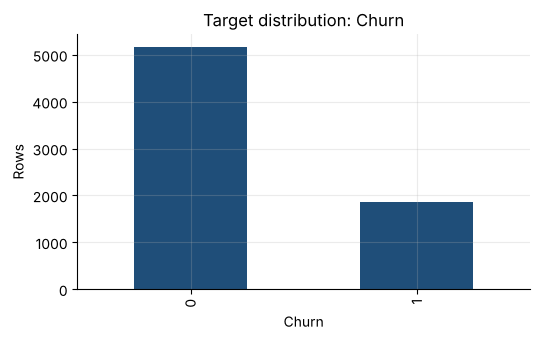

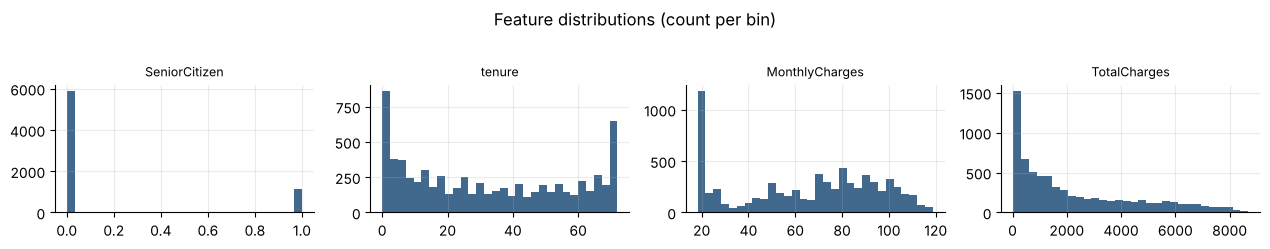

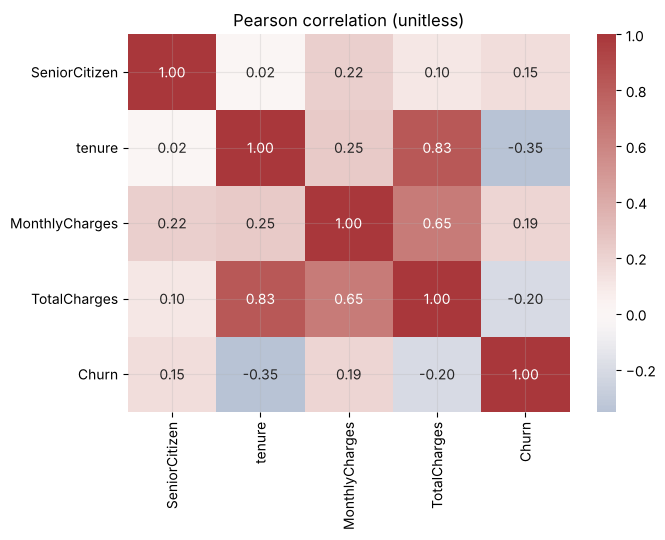

,feature,outliers,percent
0,SeniorCitizen,1142,16.21
1,tenure,0,0.00
2,MonthlyCharges,0,0.00
3,TotalCharges,0,0.00


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.

- `TotalCharges` is missing for new customers, so the median imputer is fitted on training rows only.
- Churn is the minority class, so we select models on PR-AUC (area under the precision recall curve) instead of accuracy.

In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=False, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 4225 1409 1409


,train,validation,test
Churn,,,
0,0.735,0.735,0.735
1,0.265,0.265,0.265


transformed train shape: (4225, 45)


## 8. Algorithm Implementation

### 8.1 Concept

Instead of growing the whole next level, the tree keeps splitting the single best leaf. The shape is lopsided, but each split buys the most loss reduction.

### 8.2 Python implementation from scratch

Not implemented from scratch: histogram binning and leaf-wise search are engineering optimisations. We illustrate leaf-wise gain selection on one split.

In [6]:
g = Xtr[:, 0] * 0 + (y_train.values - y_train.mean())
names = prep.get_feature_names_out()
gains = []
for j in range(Xtr.shape[1]):
    thr = np.median(Xtr[:, j])
    left = Xtr[:, j] <= thr
    if left.all() or (~left).all():
        continue
    gl, gr = g[left].sum(), g[~left].sum()
    gains.append((names[j], gl ** 2 / left.sum() + gr ** 2 / (~left).sum() - g.sum() ** 2 / len(g)))
print("best first splits by variance reduction at the median:")
display(pd.DataFrame(gains, columns=["feature", "gain"]).sort_values("gain", ascending=False).head(5).round(2))

best first splits by variance reduction at the median:


,feature,gain
14,cat__OnlineSecurity_No,100.63
23,cat__TechSupport_No,95.51
12,cat__InternetService_Fiber optic,81.50
33,cat__Contract_Two year,78.98
37,cat__PaymentMethod_Electronic check,76.96


### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `num_leaves` | Maximum leaves per tree, the main complexity knob. |
| `learning_rate`, `n_estimators` | Shrinkage and rounds. |
| `min_child_samples` | Minimum rows in a leaf. |
| `subsample`, `colsample_bytree` | Row and column sampling. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "PR_AUC"
LOWER_IS_BETTER = False
SCORING = "average_precision"
SWEEP_PARAM = "model__num_leaves"
SWEEP_VALUES = [4, 8, 15, 31, 63]

def build_pipeline():
    return make_model_pipeline(X_train, LGBMClassifier(n_estimators=200, learning_rate=0.05, min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=2, verbose=-1, random_state=SEED), scale=False, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.05, n_estimators=200,
               n_jobs=2, random_state=42, subsample=0.8, subsample_freq=1,
               verbose=-1)


,PR_AUC,Accuracy,F1,ROC_AUC,PR_AUC
model__num_leaves,,,,,
4,0.6486,0.8070,0.5916,0.8401,0.6486
8,0.6447,0.8006,0.5697,0.8388,0.6447
15,0.6350,0.7963,0.5632,0.8332,0.6350
31,0.6254,0.7913,0.5572,0.8259,0.6254
63,0.6114,0.7850,0.5511,0.8199,0.6114


best model__num_leaves on validation: 4
refit on train plus validation rows


## 10. Evaluation

Classification metrics: accuracy, precision, recall, F1, ROC-AUC and PR-AUC, plus the confusion matrix. With imbalanced classes accuracy alone misleads, so the model is chosen on F1 or PR-AUC as stated in the training cell.

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "LGBMClassifier": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="LGBMClassifier", dataset="telco_churn",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
baseline,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654
LGBMClassifier,0.8048,0.6645,0.5348,0.5926,0.8466,0.6664


5-fold CV average_precision: mean 0.6701, std 0.0236
saved lightgbm.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

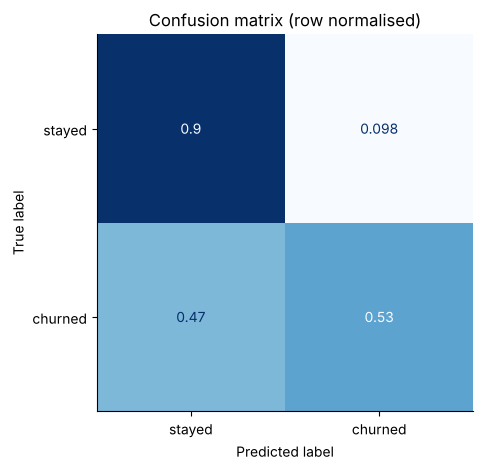

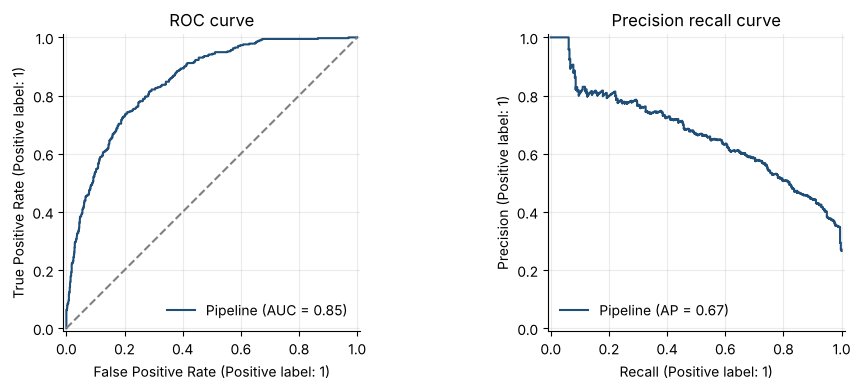

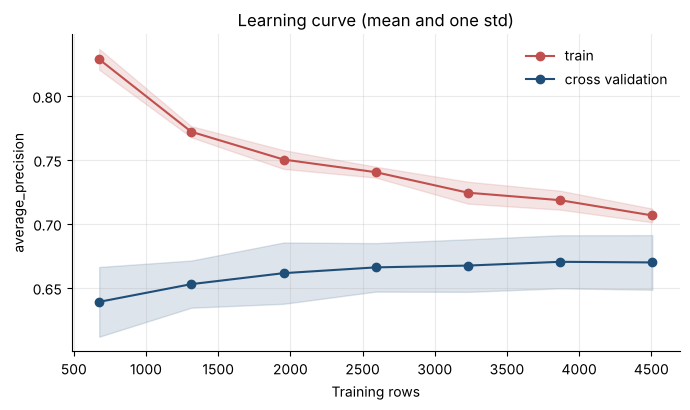

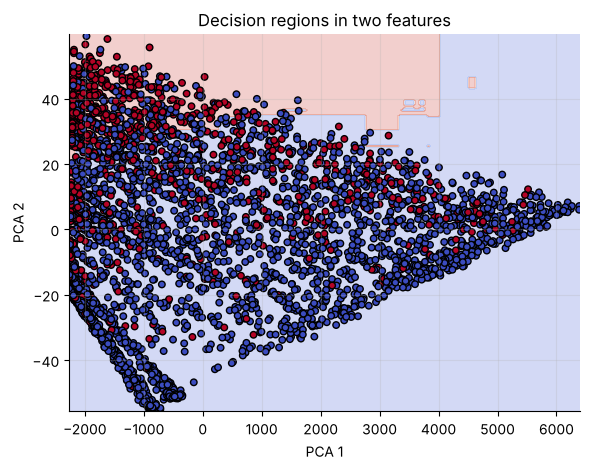

In [9]:
pred = final_model.predict(X_test)
labels = bundle.target_names or None
fig = viz.plot_confusion(y_test, pred, labels=labels)
save_figure(fig, NOTEBOOK_ID, "confusion"); plt.show()
if y_test.nunique() == 2:
    fig = viz.plot_roc_pr(final_model, X_test, y_test)
    save_figure(fig, NOTEBOOK_ID, "roc_pr"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()
# decision regions in two PCA axes
pca_view = PCA(n_components=2, random_state=SEED).fit(Xtr)
model_for_plot = clone(final_model.named_steps["model"])
fig = viz.plot_decision_boundary(lambda: clone(model_for_plot), pca_view.transform(Xtr), y_train.values,
                                 names=["PCA 1", "PCA 2"])
save_figure(fig, NOTEBOOK_ID, "decision_regions"); plt.show()

## 12. Interpretation

Permutation importance shows which inputs the model relies on. The confusion matrix shows which classes are mixed up, and the list of misclassified rows is the starting point for error analysis. A model is only as good as the cases it fails on.

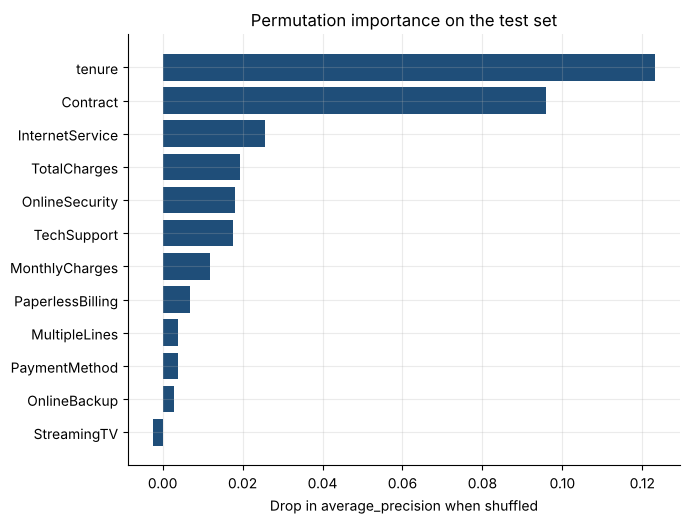

Top features: tenure, Contract, InternetService, TotalCharges, OnlineSecurity
Misclassified test rows: 275 of 1409

Test PR_AUC: 0.6664 | baseline PR_AUC: 0.2654
Cross validation spread (std): 0.0236. A test gap larger than this spread is meaningful.


In [10]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Native categorical features

Pass string columns as pandas categories and compare with one-hot encoding by cross validated PR-AUC.

In [11]:
from sklearn.model_selection import cross_val_score
Xc = X_trainval.copy()
for col in Xc.select_dtypes("object"):
    Xc[col] = Xc[col].astype("category")
params = dict(n_estimators=150, learning_rate=0.05, num_leaves=15, n_jobs=2, verbose=-1, random_state=SEED)
native = cross_val_score(LGBMClassifier(**params), Xc, y_trainval, cv=5, scoring="average_precision")
onehot = cross_val_score(make_model_pipeline(X_trainval, LGBMClassifier(**params), scale=False), X_trainval, y_trainval, cv=5, scoring="average_precision")
print(f"native categorical: CV PR-AUC {native.mean():.3f} +- {native.std(ddof=1):.3f}")
print(f"one-hot: CV PR-AUC {onehot.mean():.3f} +- {onehot.std(ddof=1):.3f}")

native categorical: CV PR-AUC 0.663 +- 0.023
one-hot: CV PR-AUC 0.660 +- 0.022


### Experiment 2: Leaves versus depth

Cap depth while keeping many leaves to see how the two controls interact.

In [12]:
from sklearn.model_selection import cross_val_score
for leaves, depth in [(31, -1), (31, 3), (8, -1), (63, 6)]:
    m = clone(final_model).set_params(model__num_leaves=leaves, model__max_depth=depth)
    s = cross_val_score(m, X_trainval, y_trainval, cv=5, scoring="average_precision")
    print(f"num_leaves={leaves}, max_depth={depth}: CV PR-AUC {s.mean():.3f} +- {s.std(ddof=1):.3f}")

num_leaves=31, max_depth=-1: CV PR-AUC 0.642 +- 0.020


num_leaves=31, max_depth=3: CV PR-AUC 0.668 +- 0.024


num_leaves=8, max_depth=-1: CV PR-AUC 0.666 +- 0.023


num_leaves=63, max_depth=6: CV PR-AUC 0.647 +- 0.020


### Experiment 3: Early stopping callback

Stop on validation log loss.

In [13]:
import lightgbm as lgb
m = LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=15, n_jobs=2, verbose=-1, random_state=SEED)
m.fit(Xtr, y_train, eval_set=[(Xva, y_val)], eval_metric="logloss", callbacks=[lgb.early_stopping(30, verbose=False)])
print("best iteration:", m.best_iteration_)

best iteration: 64


### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Change the metric used for model choice and see whether the chosen value changes.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

Ke et al. report that histogram and sampling techniques give large speedups. We do not measure scale effects here. The leaves versus depth experiment checks the qualitative point that leaf count controls complexity.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Tune `min_child_samples` and regularisation, and run repeated cross validation because differences between boosters on 7000 rows are often within noise.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- num_leaves is the key knob.
- Native categoricals can replace one-hot.
- Early stopping uses validation data only.

**Use cases.** Large tabular data and fast experiments.

**Limitations.** Overfits small data when leaves are not limited.

**Recommended next notebook.** CatBoost.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.